# EfficientNet-B3 — Evaluation Only (Celeb-DF v2, Windows 11)

This notebook **does not train or fine-tune the model**. It loads the already-saved `efficientnet_b3_best.pth` checkpoint and evaluates it on the official Celeb-DF v2 test frames extracted by the B3 training notebook.

It reports both:

- **Frame-level evaluation:** each extracted test frame is a separate prediction.
- **Video-level evaluation:** frame-level FAKE probabilities are averaged per video, producing one prediction per video.

It saves classification metrics, confusion matrices, and per-video predictions to your Windows Desktop. The training notebook must already have completed the dataset split and test-frame extraction. Stopping training early is okay as long as the `.pth` checkpoint was saved.

## 1. Imports

Use the same Python environment (`cnn_env`) that you used for EfficientNet-B3 training. No `timm` package is required.

In [1]:
import os
import sys
from pathlib import Path
from contextlib import nullcontext

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torchvision
from torchvision import datasets, transforms, models
from torchvision.transforms import InterpolationMode
from torch.utils.data import DataLoader

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score
)
from tqdm.auto import tqdm

print("Python:", sys.executable)
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available())

Python: c:\WINDOWS\system32\cnn_env\Scripts\python.exe
PyTorch: 2.11.0+cu128
Torchvision: 0.26.0+cu128
CUDA available: True


## 2. Locate the checkpoint and extracted official test frames

The default paths match the B3 training notebook. The Desktop path lookup also supports a Desktop folder redirected to OneDrive. Change `CHECKPOINT_PATH` or `TEST_FRAME_DIR` manually only if you saved the files somewhere else.

In [2]:
def get_desktop_dir():
    if os.name == "nt":
        try:
            import winreg
            with winreg.OpenKey(
                winreg.HKEY_CURRENT_USER,
                r"Software\Microsoft\Windows\CurrentVersion\Explorer\User Shell Folders"
            ) as key:
                desktop_value, _ = winreg.QueryValueEx(key, "Desktop")
            return os.path.expandvars(desktop_value)
        except (ImportError, FileNotFoundError, OSError):
            pass
    return str(Path.home() / "Desktop")

DESKTOP_DIR = get_desktop_dir()
PROJECT_DIR = os.path.join(DESKTOP_DIR, "Deepfake_Project")
CHECKPOINT_PATH = os.path.join(DESKTOP_DIR, "efficientnet_b3_best.pth")
TEST_FRAME_DIR = os.path.join(PROJECT_DIR, "celebdf_frames_b3", "test")

# Evaluation output files
METRICS_PATH = os.path.join(DESKTOP_DIR, "efficientnet_b3_test_metrics.csv")
FRAME_CM_PATH = os.path.join(DESKTOP_DIR, "efficientnet_b3_frame_confusion_matrix.png")
VIDEO_CM_PATH = os.path.join(DESKTOP_DIR, "efficientnet_b3_video_confusion_matrix.png")
VIDEO_PREDICTIONS_PATH = os.path.join(DESKTOP_DIR, "efficientnet_b3_video_predictions.csv")

print("Desktop:", DESKTOP_DIR)
print("Checkpoint:", CHECKPOINT_PATH)
print("Official test frames:", TEST_FRAME_DIR)

if not os.path.isfile(CHECKPOINT_PATH):
    raise FileNotFoundError(
        "Checkpoint not found. Confirm that efficientnet_b3_best.pth is on your Desktop "
        "or update CHECKPOINT_PATH above."
    )

if not os.path.isdir(TEST_FRAME_DIR):
    raise FileNotFoundError(
        "Official test-frame folder not found. Run the dataset split and test-frame extraction "
        "sections from the B3 training notebook first, or update TEST_FRAME_DIR above."
    )

for class_name in ["FAKE", "REAL"]:
    class_dir = os.path.join(TEST_FRAME_DIR, class_name)
    if not os.path.isdir(class_dir):
        raise FileNotFoundError(f"Missing test class folder: {class_dir}")
    image_count = sum(
        1 for name in os.listdir(class_dir)
        if name.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".webp"))
    )
    print(f"{class_name} test frames:", image_count)
    if image_count == 0:
        raise ValueError(f"No images found in {class_dir}")

Desktop: C:\Users\abdul\OneDrive\Desktop
Checkpoint: C:\Users\abdul\OneDrive\Desktop\efficientnet_b3_best.pth
Official test frames: C:\Users\abdul\OneDrive\Desktop\Deepfake_Project\celebdf_frames_b3\test
FAKE test frames: 1700
REAL test frames: 890


## 3. Load the saved checkpoint and recreate EfficientNet-B3

The model is recreated without downloading ImageNet weights because the checkpoint already contains the trained weights. Its saved class mapping and image preprocessing values are used to avoid label-order or normalization mismatches.

In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Evaluation device:", device)

# The checkpoint was created by the EfficientNet-B3 training notebook.
# PyTorch 2.6+ restricts checkpoint loading by default. Allowlist the
# TorchVersion metadata object stored in this trusted checkpoint.
try:
    from torch.torch_version import TorchVersion
    with torch.serialization.safe_globals([TorchVersion]):
        checkpoint = torch.load(
            CHECKPOINT_PATH,
            map_location=device,
            weights_only=True
        )
except (AttributeError, ImportError, TypeError):
    # Compatibility fallback for older PyTorch versions that do not support
    # safe_globals / weights_only. Use only for this trusted local checkpoint.
    try:
        checkpoint = torch.load(
            CHECKPOINT_PATH,
            map_location=device,
            weights_only=False
        )
    except TypeError:
        checkpoint = torch.load(CHECKPOINT_PATH, map_location=device)

required_keys = {
    "model_state_dict", "architecture", "num_classes",
    "class_to_idx", "input_size", "mean", "std"
}
missing_keys = required_keys.difference(checkpoint.keys())
if missing_keys:
    raise KeyError(f"Checkpoint is missing required entries: {sorted(missing_keys)}")

if checkpoint["architecture"] != "efficientnet_b3":
    raise ValueError(
        f"Expected an EfficientNet-B3 checkpoint, found: {checkpoint['architecture']}"
    )

NUM_CLASSES = int(checkpoint["num_classes"])
MODEL_NAME = checkpoint["architecture"]
SAVED_SIZE = int(checkpoint["input_size"])
SAVED_MEAN = tuple(checkpoint["mean"])
SAVED_STD = tuple(checkpoint["std"])
SAVED_CLASS_TO_IDX = {str(k): int(v) for k, v in checkpoint["class_to_idx"].items()}

model = models.efficientnet_b3(weights=None)
model.classifier[1] = nn.Linear(model.classifier[1].in_features, NUM_CLASSES)
model.load_state_dict(checkpoint["model_state_dict"])
model = model.to(device)
model.eval()

print("Architecture:", MODEL_NAME)
print("Checkpoint epoch:", checkpoint.get("epoch", "not recorded"))
print("Best validation macro F1:", checkpoint.get("best_val_macro_f1", "not recorded"))
print("Saved input size:", SAVED_SIZE)
print("Saved class mapping:", SAVED_CLASS_TO_IDX)
print("Model checkpoint loaded successfully.")

Evaluation device: cuda
Architecture: efficientnet_b3
Checkpoint epoch: 7
Best validation macro F1: 0.9424426654177704
Saved input size: 300
Saved class mapping: {'FAKE': 0, 'REAL': 1}
Model checkpoint loaded successfully.


## 4. Prepare the official test dataset

These transforms match the evaluation transforms in the training notebook: resize to 320, center-crop to the checkpoint's saved input size, and apply the checkpoint's ImageNet normalization.

In [4]:
test_transform = transforms.Compose([
    transforms.Resize(320, interpolation=InterpolationMode.BICUBIC),
    transforms.CenterCrop(SAVED_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(mean=SAVED_MEAN, std=SAVED_STD)
])

test_ds = datasets.ImageFolder(TEST_FRAME_DIR, transform=test_transform)

if test_ds.class_to_idx != SAVED_CLASS_TO_IDX:
    raise ValueError(
        "Test dataset class mapping does not match the checkpoint.\n"
        f"Test mapping: {test_ds.class_to_idx}\n"
        f"Checkpoint mapping: {SAVED_CLASS_TO_IDX}"
    )

if len(test_ds) == 0:
    raise ValueError("The official test dataset contains no images.")

class_names = [
    name for name, index in sorted(test_ds.class_to_idx.items(), key=lambda item: item[1])
]
class_to_idx = test_ds.class_to_idx
FAKE_INDEX = class_to_idx["FAKE"]
REAL_INDEX = class_to_idx["REAL"]

BATCH_SIZE = 8  # Reduce to 4 or 2 if GPU memory is insufficient.
NUM_WORKERS = 0  # Recommended for Windows notebooks.

test_loader = DataLoader(
    test_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(device.type == "cuda")
)

print("Class order:", class_names)
print("Class mapping:", class_to_idx)
print("Total official test frames:", len(test_ds))
print("Test batches:", len(test_loader))

Class order: ['FAKE', 'REAL']
Class mapping: {'FAKE': 0, 'REAL': 1}
Total official test frames: 2590
Test batches: 324


## 5. Run frame-level predictions

This runs inference only. It does not update model weights or resume training.

In [5]:
frame_true = []
frame_pred = []
frame_fake_probs = []

model.eval()
with torch.inference_mode():
    for images, labels in tqdm(test_loader, desc="Evaluating test frames"):
        images = images.to(device, non_blocking=(device.type == "cuda"))
        logits = model(images)
        probabilities = torch.softmax(logits, dim=1)
        predictions = logits.argmax(dim=1)

        frame_true.extend(labels.cpu().numpy().tolist())
        frame_pred.extend(predictions.cpu().numpy().tolist())
        frame_fake_probs.extend(probabilities[:, FAKE_INDEX].cpu().numpy().tolist())

frame_true = np.asarray(frame_true, dtype=int)
frame_pred = np.asarray(frame_pred, dtype=int)
frame_fake_probs = np.asarray(frame_fake_probs, dtype=float)

print("Frame predictions completed:", len(frame_true))

Evaluating test frames:   0%|          | 0/324 [00:00<?, ?it/s]

Frame predictions completed: 2590


## 6. Frame-level metrics and confusion matrix

The confusion matrix uses the checkpoint's class order. Rows are actual labels and columns are predicted labels.


Frame-level test classification report:
              precision    recall  f1-score   support

        FAKE     0.9613    0.9794    0.9703      1700
        REAL     0.9592    0.9247    0.9416       890

    accuracy                         0.9606      2590
   macro avg     0.9603    0.9521    0.9560      2590
weighted avg     0.9606    0.9606    0.9604      2590

Frame-level test summary:
samples: 2590
accuracy: 0.9606177606177606
balanced_accuracy: 0.9520654329147389
precision_macro: 0.9602619282180482
recall_macro: 0.9520654329147389
f1_macro: 0.9559636587668625
f1_weighted: 0.960440882637679
roc_auc_fake: 0.9930211500330469


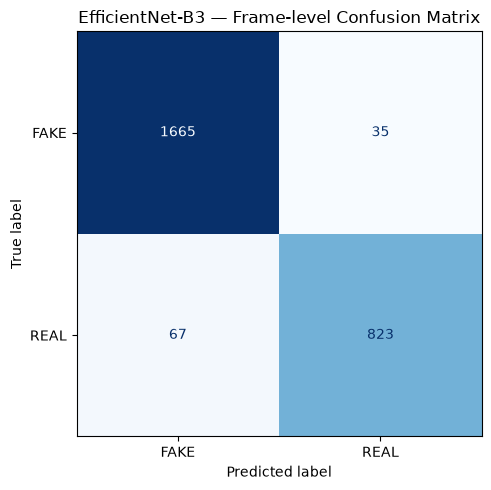

Saved confusion matrix: C:\Users\abdul\OneDrive\Desktop\efficientnet_b3_frame_confusion_matrix.png
Frame-level confusion matrix (rows=actual, columns=predicted):
      FAKE  REAL
FAKE  1665    35
REAL    67   823


In [6]:
def calculate_metrics(y_true, y_pred, fake_probabilities, evaluation_name):
    y_true = np.asarray(y_true, dtype=int)
    y_pred = np.asarray(y_pred, dtype=int)
    fake_probabilities = np.asarray(fake_probabilities, dtype=float)
    true_fake_binary = (y_true == FAKE_INDEX).astype(int)

    try:
        auc_value = roc_auc_score(true_fake_binary, fake_probabilities)
    except ValueError:
        auc_value = np.nan

    results = {
        "evaluation": evaluation_name,
        "samples": int(len(y_true)),
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "precision_macro": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "recall_macro": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "f1_weighted": f1_score(y_true, y_pred, average="weighted", zero_division=0),
        "roc_auc_fake": auc_value
    }

    print(f"\n{evaluation_name} classification report:")
    print(classification_report(
        y_true,
        y_pred,
        labels=list(range(NUM_CLASSES)),
        target_names=class_names,
        zero_division=0,
        digits=4
    ))
    print(f"{evaluation_name} summary:")
    for key, value in results.items():
        if key != "evaluation":
            print(f"{key}: {value}")
    return results


def plot_confusion_matrix(y_true, y_pred, title, output_path):
    matrix = confusion_matrix(
        y_true,
        y_pred,
        labels=list(range(NUM_CLASSES))
    )
    fig, ax = plt.subplots(figsize=(6, 5))
    display = ConfusionMatrixDisplay(
        confusion_matrix=matrix,
        display_labels=class_names
    )
    display.plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
    ax.set_title(title)
    fig.tight_layout()
    fig.savefig(output_path, dpi=200, bbox_inches="tight")
    plt.show()
    print("Saved confusion matrix:", output_path)
    return matrix

frame_metrics = calculate_metrics(
    frame_true,
    frame_pred,
    frame_fake_probs,
    "Frame-level test"
)

frame_cm = plot_confusion_matrix(
    frame_true,
    frame_pred,
    "EfficientNet-B3 — Frame-level Confusion Matrix",
    FRAME_CM_PATH
)

print("Frame-level confusion matrix (rows=actual, columns=predicted):")
print(pd.DataFrame(frame_cm, index=class_names, columns=class_names))

## 7. Aggregate frame predictions into video-level predictions

The extracted frame filenames contain the source video identifier followed by `_frame_0`, `_frame_1`, and so on. The notebook averages each video's FAKE probabilities and uses a 0.5 threshold, matching the aggregation method in the training notebook.

In [7]:
video_groups = {}

for (image_path, actual_label), fake_probability in zip(test_ds.samples, frame_fake_probs):
    frame_stem = Path(image_path).stem
    if "_frame_" not in frame_stem:
        raise ValueError(
            f"Unexpected test-frame filename: {Path(image_path).name}. "
            "Expected the training notebook's *_frame_0.jpg naming pattern."
        )
    video_id = frame_stem.rsplit("_frame_", 1)[0]

    if video_id not in video_groups:
        video_groups[video_id] = {
            "actual_label": int(actual_label),
            "fake_probabilities": []
        }
    elif video_groups[video_id]["actual_label"] != int(actual_label):
        raise ValueError(f"Inconsistent labels for frames belonging to {video_id}")

    video_groups[video_id]["fake_probabilities"].append(float(fake_probability))

video_records = []
for video_id, values in sorted(video_groups.items()):
    mean_fake_probability = float(np.mean(values["fake_probabilities"]))
    predicted_label = FAKE_INDEX if mean_fake_probability >= 0.5 else REAL_INDEX
    video_records.append({
        "video_id": video_id,
        "actual_class": class_names[values["actual_label"]],
        "predicted_class": class_names[predicted_label],
        "actual_label": values["actual_label"],
        "predicted_label": predicted_label,
        "mean_fake_probability": mean_fake_probability,
        "mean_real_probability": 1.0 - mean_fake_probability,
        "frames_evaluated": len(values["fake_probabilities"])
    })

video_predictions_df = pd.DataFrame(video_records)
video_true = video_predictions_df["actual_label"].to_numpy(dtype=int)
video_pred = video_predictions_df["predicted_label"].to_numpy(dtype=int)
video_fake_probs = video_predictions_df["mean_fake_probability"].to_numpy(dtype=float)

print("Videos evaluated:", len(video_predictions_df))
print("Video-level predictions (first rows):")
display(video_predictions_df.head())

Videos evaluated: 518
Video-level predictions (first rows):


,video_id,actual_class,predicted_class,actual_label,predicted_label,mean_fake_probability,mean_real_probability,frames_evaluated
0,Celeb-real_id0_0001,REAL,REAL,1,1,0.002930,0.997070,5
1,Celeb-real_id10_0001,REAL,REAL,1,1,0.363657,0.636343,5
2,Celeb-real_id10_0007,REAL,REAL,1,1,0.039849,0.960151,5
3,Celeb-real_id11_0006,REAL,REAL,1,1,0.004661,0.995339,5
4,Celeb-real_id11_0008,REAL,REAL,1,1,0.238803,0.761197,5


## 8. Video-level metrics and confusion matrix

Video-level results are especially relevant if your deployed system makes one REAL/FAKE decision for an entire video rather than for each individual frame.


Video-level test classification report:
              precision    recall  f1-score   support

        FAKE     0.9713    0.9941    0.9826       340
        REAL     0.9882    0.9438    0.9655       178

    accuracy                         0.9768       518
   macro avg     0.9797    0.9690    0.9740       518
weighted avg     0.9771    0.9768    0.9767       518

Video-level test summary:
samples: 518
accuracy: 0.9768339768339769
balanced_accuracy: 0.9689689358889624
precision_macro: 0.9797498309668695
recall_macro: 0.9689689358889624
f1_macro: 0.9740376904570971
f1_weighted: 0.9767023868868294
roc_auc_fake: 0.9969927296761402


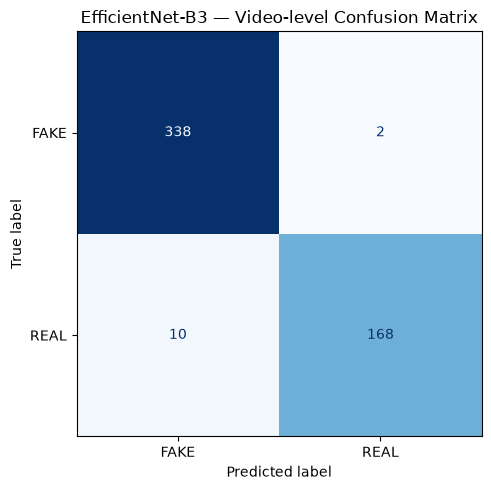

Saved confusion matrix: C:\Users\abdul\OneDrive\Desktop\efficientnet_b3_video_confusion_matrix.png
Video-level confusion matrix (rows=actual, columns=predicted):
      FAKE  REAL
FAKE   338     2
REAL    10   168


In [8]:
video_metrics = calculate_metrics(
    video_true,
    video_pred,
    video_fake_probs,
    "Video-level test"
)

video_cm = plot_confusion_matrix(
    video_true,
    video_pred,
    "EfficientNet-B3 — Video-level Confusion Matrix",
    VIDEO_CM_PATH
)

print("Video-level confusion matrix (rows=actual, columns=predicted):")
print(pd.DataFrame(video_cm, index=class_names, columns=class_names))

## 9. Save evaluation results to the Desktop

The checkpoint is not modified. These files contain the evaluation results from the saved best checkpoint.

In [9]:
metrics_df = pd.DataFrame([frame_metrics, video_metrics])
metrics_df.to_csv(METRICS_PATH, index=False)
video_predictions_df.to_csv(VIDEO_PREDICTIONS_PATH, index=False)

print("Evaluation complete.")
print("\nSaved files:")
print("Metrics:", METRICS_PATH)
print("Frame confusion matrix:", FRAME_CM_PATH)
print("Video confusion matrix:", VIDEO_CM_PATH)
print("Per-video predictions:", VIDEO_PREDICTIONS_PATH)

display(metrics_df)

Evaluation complete.

Saved files:
Metrics: C:\Users\abdul\OneDrive\Desktop\efficientnet_b3_test_metrics.csv
Frame confusion matrix: C:\Users\abdul\OneDrive\Desktop\efficientnet_b3_frame_confusion_matrix.png
Video confusion matrix: C:\Users\abdul\OneDrive\Desktop\efficientnet_b3_video_confusion_matrix.png
Per-video predictions: C:\Users\abdul\OneDrive\Desktop\efficientnet_b3_video_predictions.csv


,evaluation,samples,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,roc_auc_fake
0,Frame-level test,2590,0.960618,0.952065,0.960262,0.952065,0.955964,0.960441,0.993021
1,Video-level test,518,0.976834,0.968969,0.979750,0.968969,0.974038,0.976702,0.996993


## Important interpretation notes

- The checkpoint is the **best validation macro-F1 checkpoint saved before you stopped training**, not necessarily the checkpoint that would have resulted from completing all planned epochs.
- These results measure the checkpoint you already have; they do not resume or alter training.
- The official test split must remain untouched while choosing model settings. Do not repeatedly tune the model or the 0.5 decision threshold based on test results.
- Frame-level scores count each sampled frame. Video-level scores count each video once and are more directly aligned with a video-classification application.
- The default video aggregation is the mean FAKE probability across sampled frames with a 0.5 threshold, matching the original training notebook.